### Check distributions of number of active pixels

From Pereira et al. Landat fire mask dataset:


Auditing Dataset Source: NA1 (North America Split 1)
Extracting sample chunk: 150 of 732 sub-archives...
Isolated 744 target mask files for metrics profiling.

Distribution Profiling Summary for NA1 (North America Split 1):
  Total masks evaluated: 744
  Empty patches (0 px):   0 (0.0%)
  Sparse patches (1-5 px): 644
  Dense fire (>200 px):    4
  Descriptive Stats (Min/Med/Mean/Max): 1 / 2.0 / 6.1 / 390

Auditing Dataset Source: NA2 (North America Split 2)
Extracting sample chunk: 150 of 450 sub-archives...
Isolated 76 target mask files for metrics profiling.

Distribution Profiling Summary for NA2 (North America Split 2):
  Total masks evaluated: 76
  Empty patches (0 px):   0 (0.0%)
  Sparse patches (1-5 px): 64
  Dense fire (>200 px):    0
  Descriptive Stats (Min/Med/Mean/Max): 1 / 2.0 / 5.1 / 96

Auditing Dataset Source: SA (South America)
Extracting sample chunk: 150 of 594 sub-archives...
Isolated 804 target mask files for metrics profiling.

Distribution Profiling Summary for

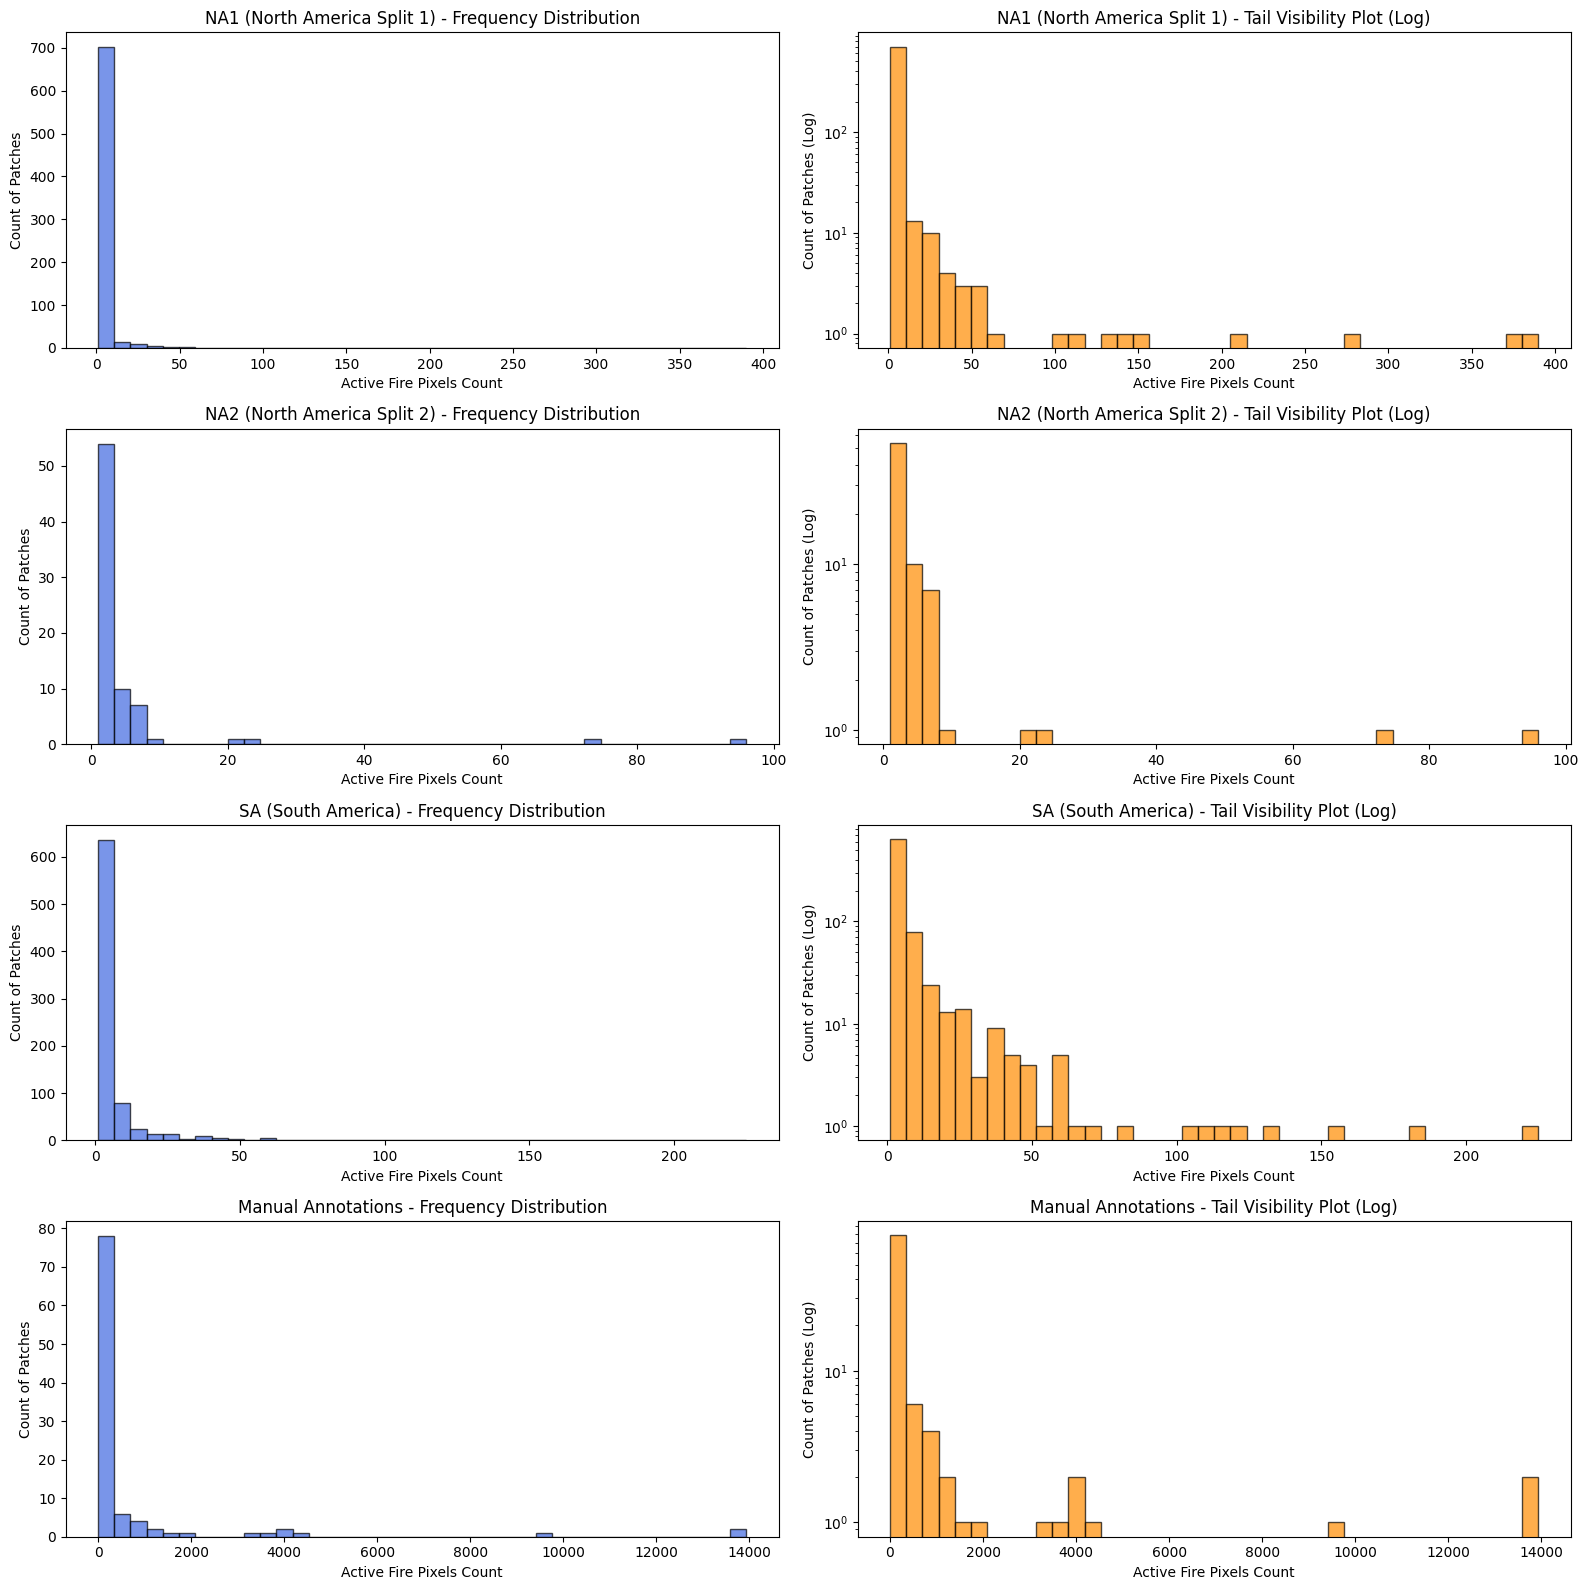

In [1]:
import os
import io
import re
import glob
import zipfile
import gdown
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

DATASET_CONFIGS = {
    "NA1 (North America Split 1)": {
        "drive_id": "1BXRGldTdGGNeWDOFqNnmiNPuPQjweB2M", 
        "is_flat": False,
        "mask_pattern": "*intersection*.tif"
    },
    "NA2 (North America Split 2)": {
        "drive_id": "1zW_pEIggJ5Li7uQX9XKMfHkcgL3kiUoi",
        "is_flat": False,
        "mask_pattern": "*intersection*.tif"
    },
    "SA (South America)": {
        "drive_id": "1hnBUmYkvFYohTf9hTnKiyp2MXVevglK7",
        "is_flat": False,
        "mask_pattern": "*intersection*.tif"
    },
    "Manual Annotations": {
        "drive_id": "1LdsX-rH5hy_82jfc1akO8p4n0_N8lRgf",
        "is_flat": True,
        "mask_pattern": "*.tif*"
    }
}

# Execution parameters
MAX_SUB_ARCHIVES_TO_SAMPLE = 150  # Keep sampling uniform across nested datasets
BASE_TMP_DIR = "/tmp/dataset_audit"
os.makedirs(BASE_TMP_DIR, exist_ok=True)

all_results = {}

for name, cfg in DATASET_CONFIGS.items():
    print(f"\n{'='*60}\nAuditing Dataset Source: {name}\n{'='*60}")
    
    zip_path = os.path.join(BASE_TMP_DIR, f"{re.sub(r'[^a-zA-Z0-9]', '_', name)}.zip")
    extract_dir = os.path.join(BASE_TMP_DIR, f"{re.sub(r'[^a-zA-Z0-9]', '_', name)}_extracted")
    os.makedirs(extract_dir, exist_ok=True)
    
    # 1. Download source from Google Drive if not locally cached
    if not os.path.exists(zip_path):
        print(f"Downloading source archive from Google Drive...")
        try:
            gdown.download(id=cfg['drive_id'], output=zip_path, quiet=False)
        except Exception as e:
            print(f"Skipping {name}: Download failed ({e})")
            continue

    active_counts = []
    
    # 2. Extract contents based on archive structure topology
    with zipfile.ZipFile(zip_path, 'r') as parent:
        if not cfg['is_flat']:
            # Nested structure parsing
            nested_zips = [f for f in parent.namelist() if f.endswith('.zip') and 'masks' in f.lower()]
            sample_size = min(len(nested_zips), MAX_SUB_ARCHIVES_TO_SAMPLE)
            print(f"Extracting sample chunk: {sample_size} of {len(nested_zips)} sub-archives...")
            
            for n_name in nested_zips[:sample_size]:
                with parent.open(n_name) as n_file:
                    with zipfile.ZipFile(io.BytesIO(n_file.read())) as child:
                        child.extractall(extract_dir)
        else:
            # Flat archive parsing
            print(f"Flat archive detected. Unpacking target GeoTIFF arrays...")
            parent.extractall(extract_dir)
            
    # 3. Locate target files matching mask rules
    tif_paths = glob.glob(os.path.join(extract_dir, "**", cfg['mask_pattern']), recursive=True)
    total_masks = len(tif_paths)
    print(f"Isolated {total_masks} target mask files for metrics profiling.")
    
    if total_masks == 0:
        print(f"No matching files found for pattern: {cfg['mask_pattern']}")
        continue

    # 4. Profile pixel matrices
    for path in tif_paths:
        try:
            with rasterio.open(path) as src:
                mask = src.read(1)
            # Count pixels matching the active fire condition
            active_counts.append(int(np.sum(mask == 1)))
        except Exception as e:
            print(f"Warning: Corrupted image file skipped: {path} -> {e}")

    active_counts = np.array(active_counts)
    all_results[name] = active_counts
    
    # 5. Output localized text summary metrics
    print(f"\nDistribution Profiling Summary for {name}:")
    print(f"  Total masks evaluated: {len(active_counts)}")
    print(f"  Empty patches (0 px):   {(active_counts == 0).sum()} ({(active_counts == 0).sum()/len(active_counts)*100:.1f}%)")
    print(f"  Sparse patches (1-5 px): {((active_counts >= 1) & (active_counts <= 5)).sum()}")
    print(f"  Dense fire (>200 px):    {(active_counts > 200).sum()}")
    print(f"  Descriptive Stats (Min/Med/Mean/Max): {active_counts.min()} / {np.median(active_counts):.1f} / {active_counts.mean():.1f} / {active_counts.max()}")

# 6. Global Comparative Visualization
if all_results:
    fig, axes = plt.subplots(len(all_results), 2, figsize=(16, 4 * len(all_results)))
    if len(all_results) == 1:
        axes = np.expand_dims(axes, axis=0) # Normalize layout tracking array dimensions
        
    for idx, (name, counts) in enumerate(all_results.items()):
        # Standard Linear Histogram
        axes[idx, 0].hist(counts, bins=40, color='royalblue', edgecolor='black', alpha=0.7)
        axes[idx, 0].set_title(f"{name} - Frequency Distribution")
        axes[idx, 0].set_xlabel("Active Fire Pixels Count")
        axes[idx, 0].set_ylabel("Count of Patches")
        
        # Log Scale Tail Histogram
        axes[idx, 1].hist(counts[counts > 0], bins=40, color='darkorange', edgecolor='black', alpha=0.7)
        axes[idx, 1].set_yscale('log')
        axes[idx, 1].set_title(f"{name} - Tail Visibility Plot (Log)")
        axes[idx, 1].set_xlabel("Active Fire Pixels Count")
        axes[idx, 1].set_ylabel("Count of Patches (Log)")
        
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_TMP_DIR, "dataset_comparative_distributions.png"), dpi=150)
    plt.show()

### Check how many masks are contained

In [4]:
import io
import gdown
import zipfile

def count_total_masks_instant(file_source, is_flat=False):
    """
    Scans zip central directory metadata from an in-memory BytesIO buffer 
    to instantly calculate absolute mask volumes.
    """
    total_mask_count = 0
    with zipfile.ZipFile(file_source, 'r') as parent:
        if is_flat:
            total_mask_count = sum(1 for f in parent.namelist() if f.lower().endswith(('.tif', '.tiff')))
        else:
            nested_zips = [f for f in parent.namelist() if f.endswith('.zip') and 'masks' in f.lower()]
            print(f"Analyzing internal metadata for {len(nested_zips)} sub-archives...")
            for n_name in nested_zips:
                with parent.open(n_name) as n_file:
                    with zipfile.ZipFile(io.BytesIO(n_file.read())) as child:
                        total_mask_count += sum(1 for f in child.namelist() if 'intersection' in f.lower() and f.endswith('.tif'))
    return total_mask_count

# Run the mask volume quantification check
print(f"{'='*60}\nEstimating Complete Operational Workload\n{'='*60}")
for name, cfg in DATASET_CONFIGS.items():
    print(f"\nStreaming index metadata for {name}...")
    try:
        meta_buffer = io.BytesIO()
        # Fixed: using id instead of url, removed remaining_ok
        gdown.download(id=cfg['drive_id'], output=meta_buffer, quiet=True)
        meta_buffer.seek(0)
        
        absolute_total = count_total_masks_instant(meta_buffer, is_flat=cfg['is_flat'])
        print(f"  --> Full Remote Archive contains: {absolute_total:,} target GeoTIFF masks.")
    except Exception as e:
        print(f"  --> Metadata parsing failed: {e}")

Estimating Complete Operational Workload

Streaming index metadata for NA1 (North America Split 1)...
Analyzing internal metadata for 732 sub-archives...
  --> Full Remote Archive contains: 3,764 target GeoTIFF masks.

Streaming index metadata for NA2 (North America Split 2)...
Analyzing internal metadata for 450 sub-archives...
  --> Full Remote Archive contains: 452 target GeoTIFF masks.

Streaming index metadata for SA (South America)...
Analyzing internal metadata for 594 sub-archives...
  --> Full Remote Archive contains: 5,696 target GeoTIFF masks.

Streaming index metadata for Manual Annotations...
  --> Full Remote Archive contains: 100 target GeoTIFF masks.


Total: 10,012

Assuming 80% of data will be filtered after filtering for >= 10 active pixels, we will get roughly 2,000 target masks.

### Check how many raster data we get from the VIIRS csv data

In [7]:
import pandas as pd
import numpy as np

# =====================================================================
# 1. PIPELINE CONFIGURATION MATCHING final-pipeline.py
# =====================================================================
VIIRS_CSV_PATH = os.path.expanduser("~/irp-th25/src/data/raw_viirs/fire_archive_SV-C2_762484.csv")
VIIRS_DATE_RANGE = ("2020-08-01", "2020-09-30")
VIIRS_TARGET_EXTENT_M = 7500  # 20 pixels * 375m grid spacing

# Spatial bounding box derived from your prior Landsat run 
# (If you want to evaluate the total absolute global pool, set this to None)
REGION_BBOX = [-170.0, -56.0, -30.0, 75.0]  # Default Americas Extent

# =====================================================================
# 2. LOAD & FILTER CATALOG
# =====================================================================
print("Loading NASA VIIRS Archive CSV...")
df = pd.read_csv(VIIRS_CSV_PATH)
df.columns = df.columns.str.strip()
df['acq_date'] = pd.to_datetime(df['acq_date'])

# Apply Confidence Filter
if 'confidence' in df.columns:
    df['confidence'] = df['confidence'].astype(str).str.strip().str.lower()
    df = df[df['confidence'].isin(['n', 'h', 'nominal', 'high'])]

# Apply Temporal Filter
df = df[(df['acq_date'] >= VIIRS_DATE_RANGE[0]) & (df['acq_date'] <= VIIRS_DATE_RANGE[1])]

# Apply Spatial Region Filter
if REGION_BBOX:
    df = df[
        (df['longitude'] >= REGION_BBOX[0]) & (df['longitude'] <= REGION_BBOX[2]) &
        (df['latitude'] >= REGION_BBOX[1]) & (df['latitude'] <= REGION_BBOX[3])
    ]

print(f"Total underlying point-detections matching filters: {len(df):,}")

# =====================================================================
# 3. COMPUTE CLUSTER WORKLOAD (Raster Cells)
# =====================================================================
# Convert 7,500m target extent to rough degree grid intervals
cell_deg = VIIRS_TARGET_EXTENT_M / 111320.0

df['cell_lon'] = (df['longitude'] // cell_deg).astype(int)
df['cell_lat'] = (df['latitude'] // cell_deg).astype(int)
df['date_str'] = df['acq_date'].dt.strftime('%Y%m%d')

# Distinct combinations of [Date, Grid-X, Grid-Y] define our final rasters
unique_clusters = df.groupby(['date_str', 'cell_lon', 'cell_lat']).size()
total_rasters = len(unique_clusters)

print(f"\n{'='*50}\nVIIRS WORKLOAD ESTIMATION SUMMARY\n{'='*50}")
print(f"Expected Number of VIIRS Raster Files: {total_rasters:,}")
print(f"Average point detections compressed per raster: {unique_clusters.mean():.1f}")
print(f"Max point detections in a single raster cell:  {unique_clusters.max()}")
print(f"{'='*50}")

Loading NASA VIIRS Archive CSV...
Total underlying point-detections matching filters: 1,622,078

VIIRS WORKLOAD ESTIMATION SUMMARY
Expected Number of VIIRS Raster Files: 361,225
Average point detections compressed per raster: 4.5
Max point detections in a single raster cell:  423


361,225 raster data is a lot, so we will need to cap the number of raster data we save.

### Count number of active pixels in rasterised VIIRS 

Loading and filtering VIIRS catalog...

Distribution Profiling Summary for VIIRS Rasters:
  Total rasters evaluated: 361,225
  Empty patches (0 px):   0 (0.0%)  <-- (Points are explicitly filtered into groups)
  Sparse patches (1-5 px): 299,775 (83.0%)
  Dense fire (>200 px):    132
  Descriptive Stats (Min/Med/Mean/Max): 1 / 2.0 / 4.5 / 423


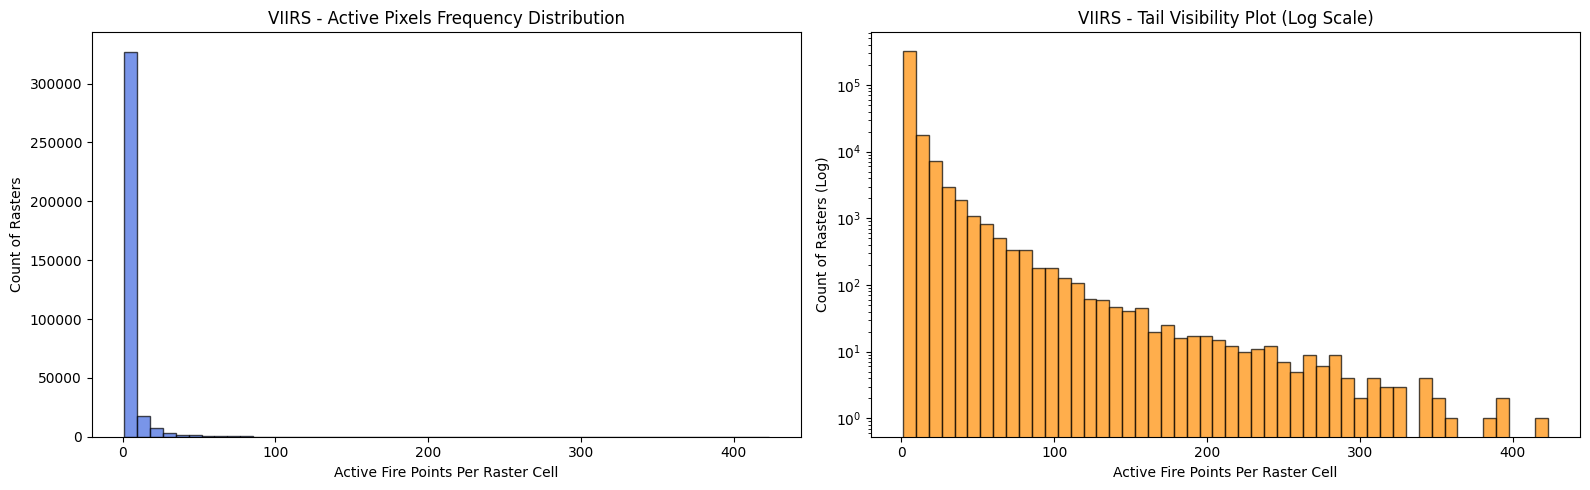

In [8]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =====================================================================
# 1. SETUP PATHS AND PARAMETERS (Matching your pipeline logic)
# =====================================================================
VIIRS_CSV_PATH = os.path.expanduser("~/irp-th25/src/data/raw_viirs/fire_archive_SV-C2_762484.csv")
VIIRS_DATE_RANGE = ("2020-08-01", "2020-09-30")
VIIRS_TARGET_EXTENT_M = 7500  # 7.5km box
REGION_BBOX = [-170.0, -56.0, -30.0, 75.0]  # Americas bounds

# =====================================================================
# 2. LOAD AND FILTER CSV
# =====================================================================
print("Loading and filtering VIIRS catalog...")
df = pd.read_csv(VIIRS_CSV_PATH)
df.columns = df.columns.str.strip()
df['acq_date'] = pd.to_datetime(df['acq_date'])

# Apply structural pipeline filters
if 'confidence' in df.columns:
    df['confidence'] = df['confidence'].astype(str).str.strip().str.lower()
    df = df[df['confidence'].isin(['n', 'h', 'nominal', 'high'])]

df = df[(df['acq_date'] >= VIIRS_DATE_RANGE[0]) & (df['acq_date'] <= VIIRS_DATE_RANGE[1])]

if REGION_BBOX:
    df = df[
        (df['longitude'] >= REGION_BBOX[0]) & (df['longitude'] <= REGION_BBOX[2]) &
        (df['latitude'] >= REGION_BBOX[1]) & (df['latitude'] <= REGION_BBOX[3])
    ]

# =====================================================================
# 3. GRID MAPPING & AGGREGATION (Simulating Rasterization)
# =====================================================================
cell_deg = VIIRS_TARGET_EXTENT_M / 111320.0
df['cell_lon'] = (df['longitude'] // cell_deg).astype(int)
df['cell_lat'] = (df['latitude'] // cell_deg).astype(int)
df['date_str'] = df['acq_date'].dt.strftime('%Y%m%d')

# Count how many individual points fall into each raster cell group
# (This represents the number of active fire pixels that will be painted onto your raster)
active_counts = df.groupby(['date_str', 'cell_lon', 'cell_lat']).size().to_numpy()

# =====================================================================
# 4. OUTPUT SUMMARY METRICS
# =====================================================================
print(f"\n{'='*60}\nDistribution Profiling Summary for VIIRS Rasters:\n{'='*60}")
print(f"  Total rasters evaluated: {len(active_counts):,}")
print(f"  Empty patches (0 px):   0 (0.0%)  <-- (Points are explicitly filtered into groups)")
print(f"  Sparse patches (1-5 px): {((active_counts >= 1) & (active_counts <= 5)).sum():,} ({((active_counts >= 1) & (active_counts <= 5)).sum()/len(active_counts)*100:.1f}%)")
print(f"  Dense fire (>200 px):    {(active_counts > 200).sum():,}")
print(f"  Descriptive Stats (Min/Med/Mean/Max): {active_counts.min()} / {np.median(active_counts):.1f} / {active_counts.mean():.1f} / {active_counts.max()}")

# =====================================================================
# 5. VISUALIZATION
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Linear Histogram
axes[0].hist(active_counts, bins=50, color='royalblue', edgecolor='black', alpha=0.7)
axes[0].set_title("VIIRS - Active Pixels Frequency Distribution")
axes[0].set_xlabel("Active Fire Points Per Raster Cell")
axes[0].set_ylabel("Count of Rasters")

# Log Scale Histogram for tail visibility
axes[1].hist(active_counts, bins=50, color='darkorange', edgecolor='black', alpha=0.7)
axes[1].set_yscale('log')
axes[1].set_title("VIIRS - Tail Visibility Plot (Log Scale)")
axes[1].set_xlabel("Active Fire Points Per Raster Cell")
axes[1].set_ylabel("Count of Rasters (Log)")

plt.tight_layout()
plt.show()

### Data visualisation (after running pipeline)

In [4]:
import io
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import rasterio
import random
from rasterio.plot import show
from google.cloud import storage
from google.auth import default

BUCKET_NAME = 'wildfire-irp-data-th25'
OUTPUT_PREFIX = 'processed_dataset_gcp'
N_SAMPLES = 5  # how many samples to plot per branch

credentials, _ = default()
bucket = storage.Client(credentials=credentials).bucket(BUCKET_NAME)
print('Connected to GCS bucket.')

Connected to GCS bucket.


In [5]:
def read_tif_from_gcs(gcs_path):
    blob = bucket.blob(gcs_path)
    if not blob.exists():
        return None, None
    raw = blob.download_as_bytes()
    with rasterio.MemoryFile(raw) as mf:
        with mf.open() as src:
            data = src.read().astype(np.float32)
            nodata = src.nodata
    # Fill nodata and NaN with 0
    if nodata is not None:
        data[data == nodata] = 0.0
    data[~np.isfinite(data)] = 0.0
    return data, None

def get_random_samples(branch, count=3):
    """
    Fast lazy sampling:
    1. Fetches only the blob metadata names (fast API call, no content download).
    2. Shuffles the list.
    3. Downloads JSON and target files one-by-one until 'count' valid samples are found.
    """
    prefix = f'{OUTPUT_PREFIX}/{branch}/manifest/'
    
    # List blob metadata without downloading content
    blobs = [b for b in bucket.list_blobs(prefix=prefix) if b.name.endswith('.json')]
    if not blobs:
        print(f'No manifests found for branch: {branch}')
        return []
    
    # Shuffle manifest paths randomly
    random.shuffle(blobs)
    
    valid_samples = []
    for blob in blobs:
        # Download manifest JSON for selected blob
        manifest = json.loads(blob.download_as_text())
        target_path = manifest['paths']['target'].lstrip('/')
        
        # Download and evaluate target GeoTIFF
        data, _ = read_tif_from_gcs(target_path)
        if data is None or np.all(data == 0):
            continue
            
        valid_samples.append(manifest)
        if len(valid_samples) == count:
            break
            
    return valid_samples

def normalise(arr, pct_lo=2, pct_hi=98, exclude_zeros=False):
    """Percentile stretch to [0,1] for display, ignoring NaN/nodata."""
    valid = arr[np.isfinite(arr)]
    if exclude_zeros:
        valid = valid[valid != 0]
    if valid.size == 0:
        return np.zeros_like(arr, dtype=float)
    lo, hi = np.percentile(valid, [pct_lo, pct_hi])
    if hi == lo:
        return np.zeros_like(arr, dtype=float)
    return np.clip((arr.astype(float) - lo) / (hi - lo), 0, 1)

def sparsity(arr):
    """Fraction of pixels that are NOT active fire (value == 1)."""
    total = arr.size
    active = np.sum(arr > 0.5)  # fire pixels
    return 1.0 - (active / total) if total > 0 else 1.0

def classify_sparsity(arr):
    s = sparsity(arr)
    if s > 0.95:
        return f'SPARSE ({s * 100:.1f}% empty)'
    elif s > 0.5:
        return f'moderate ({s * 100:.1f}% empty)'
    else:
        return f'dense ({s * 100:.1f}% empty)'

# ESA WorldCover palette (class value → colour)
LC_CMAP = mcolors.ListedColormap([
    '#006400',  # 10 Trees
    '#ffbb22',  # 20 Shrubland
    '#ffff4c',  # 30 Grassland
    '#f096ff',  # 40 Cropland
    '#fa0000',  # 50 Built-up
    '#b4b4b4',  # 60 Bare / sparse vegetation
    '#f0f0f0',  # 70 Snow and ice
    '#0064c8',  # 80 Permanent water
    '#0096a0',  # 90 Herbaceous wetland
    '#00cf75',  # 95 Mangroves
    '#fae6a0',  # 100 Moss and lichen
])

print('Helpers defined.')

Helpers defined.


In [20]:
print('Fetching random samples...')
ls_samples = get_random_samples('landsat_pairs', count=N_SAMPLES)
viirs_samples = get_random_samples('viirs_pairs', count=N_SAMPLES)

print(f'Selected {len(ls_samples)} Landsat samples, {len(viirs_samples)} VIIRS samples.')

Fetching random samples...
Selected 5 Landsat samples, 5 VIIRS samples.


Plotting Landsat samples...


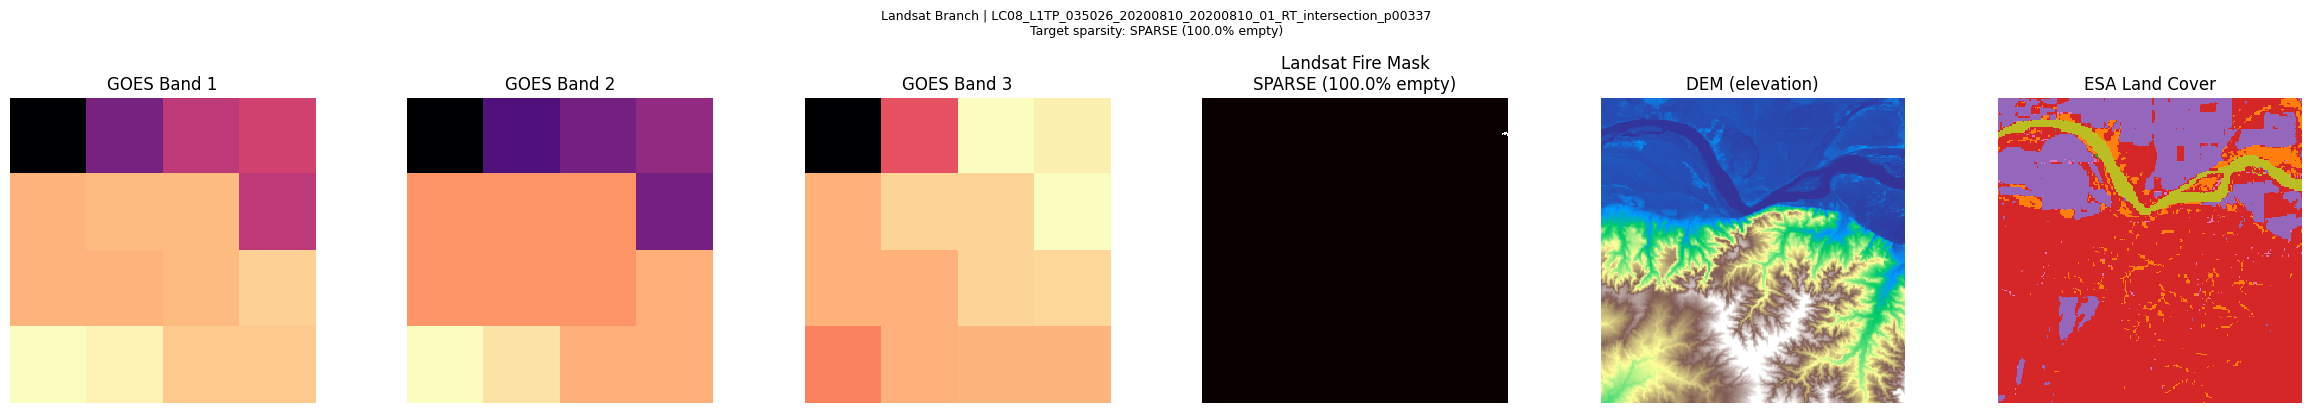

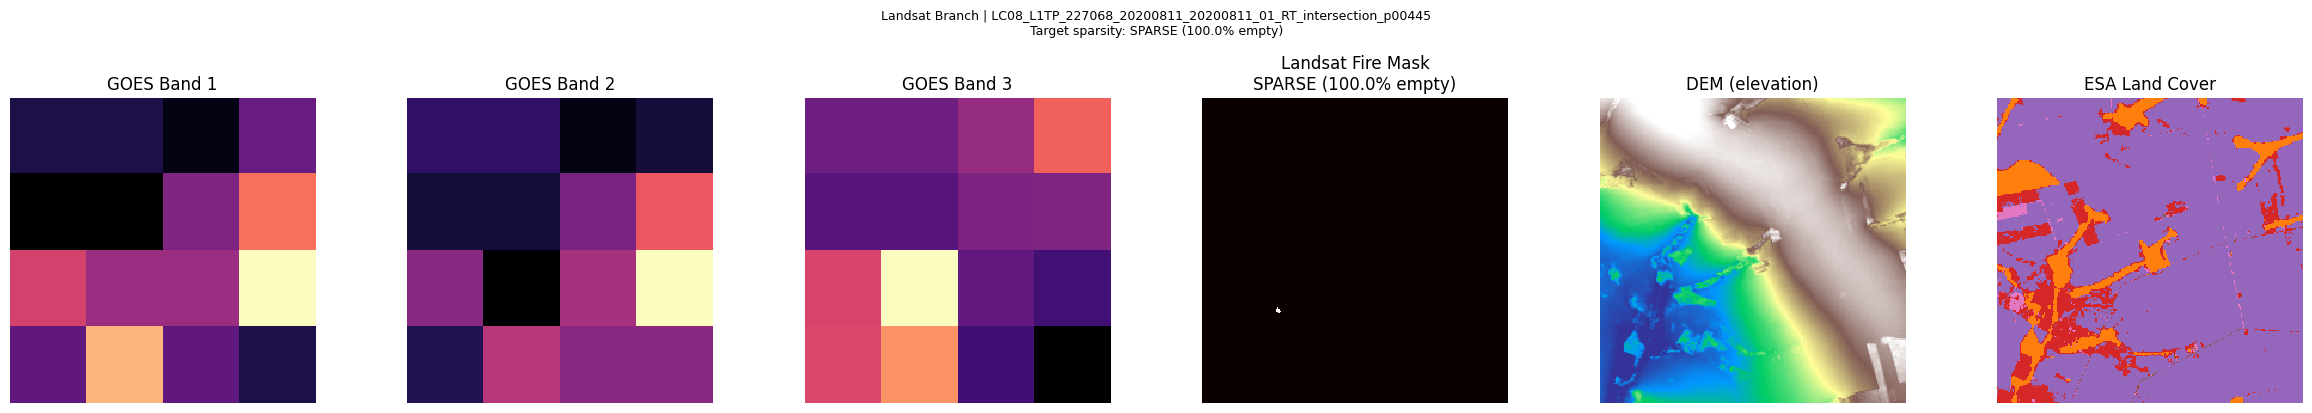

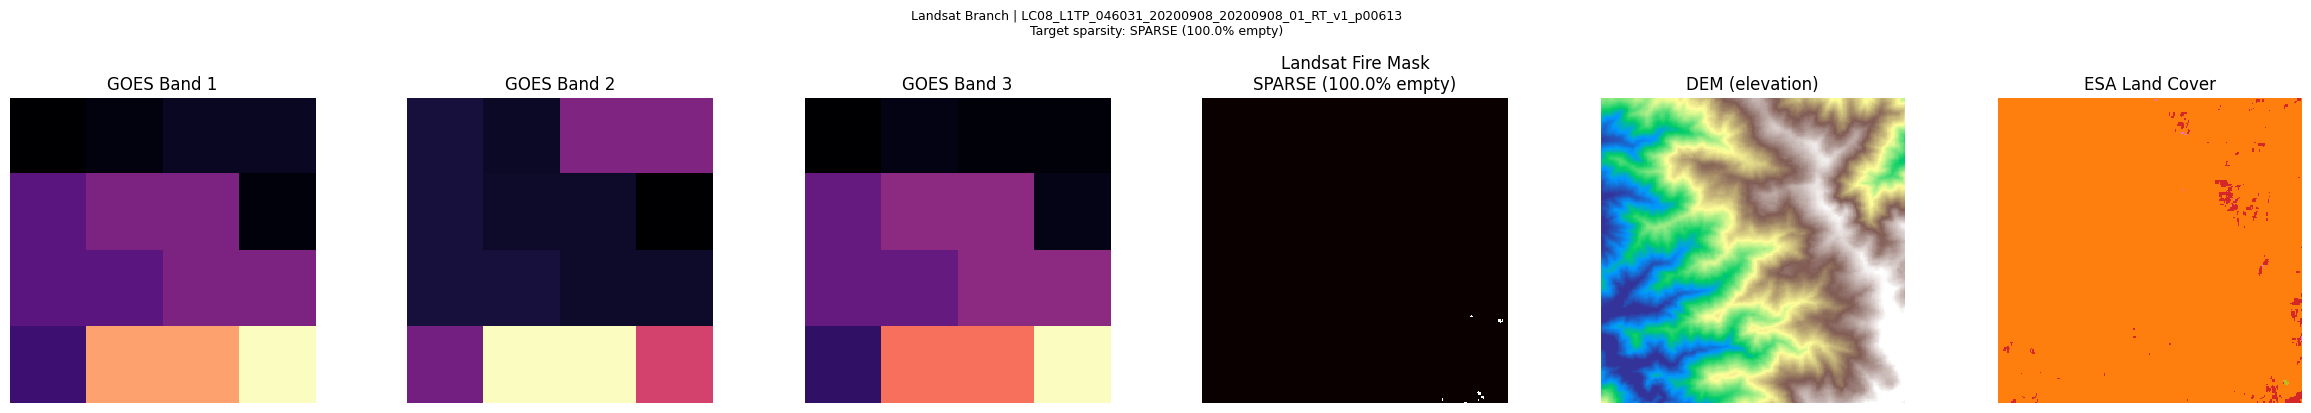

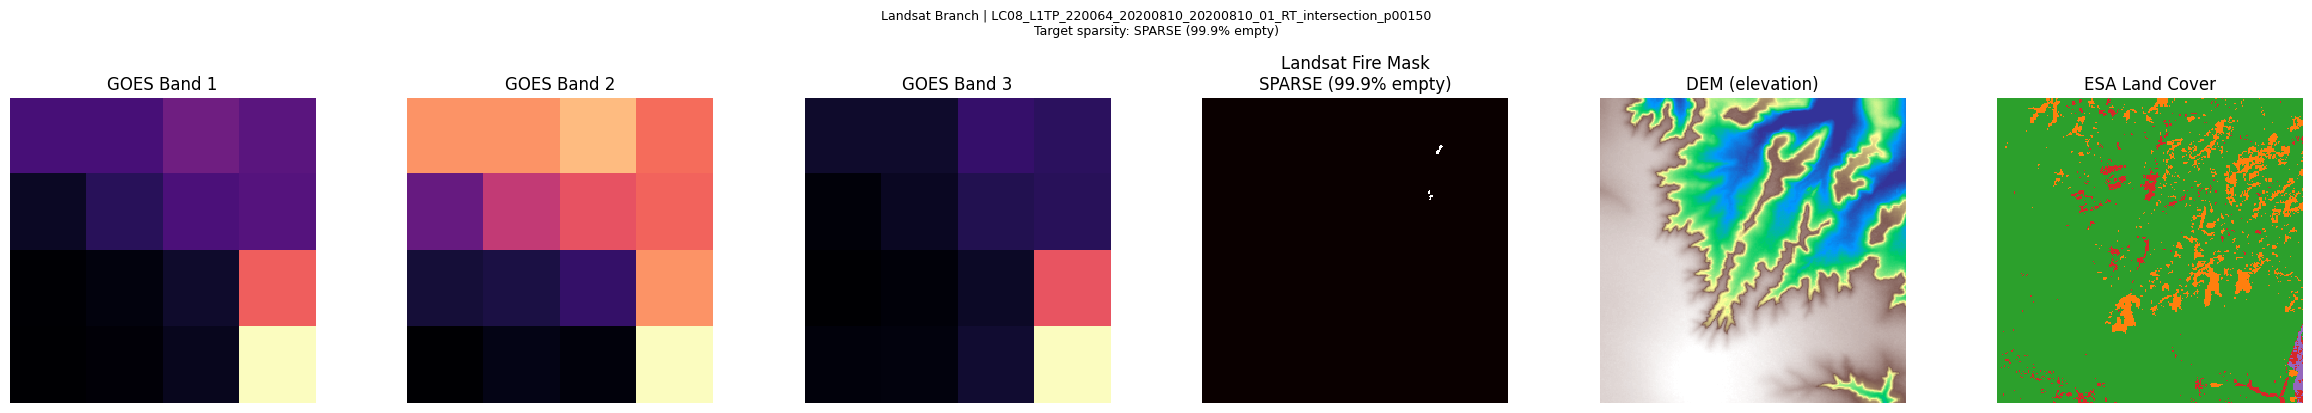

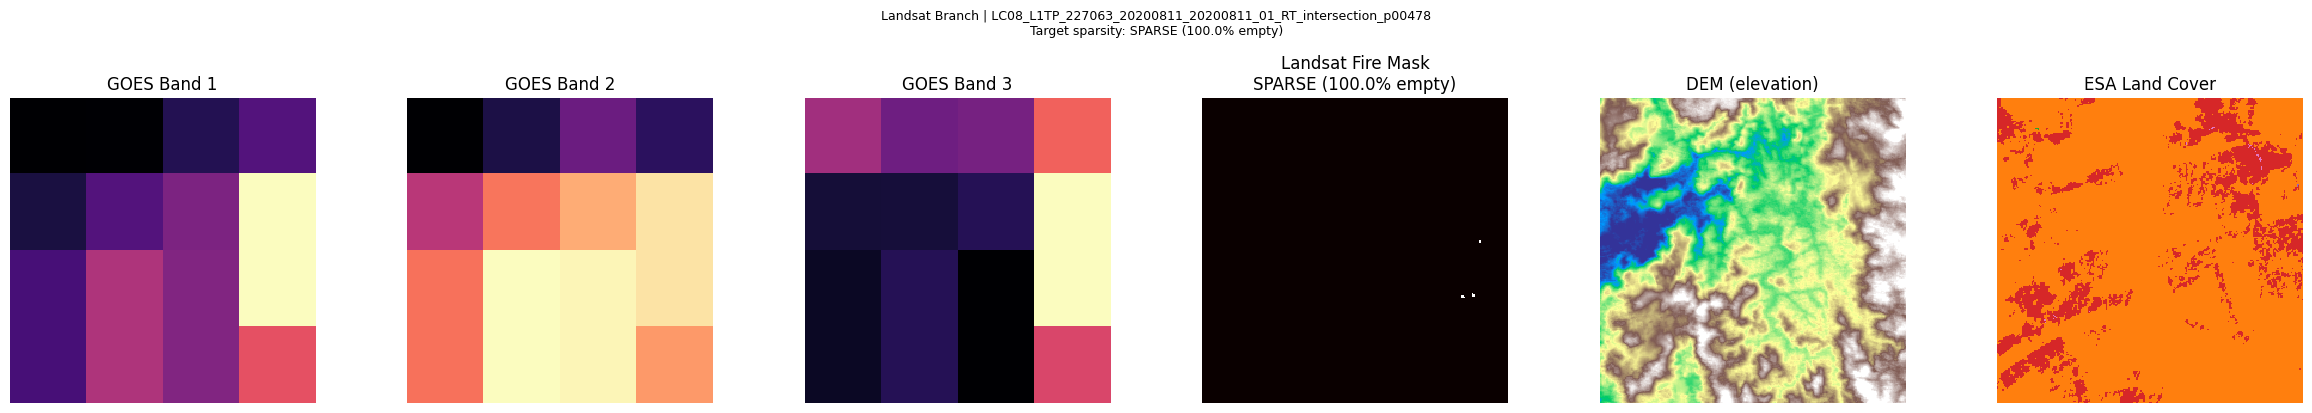

In [21]:
# ── Plot: GOES / Landsat / DEM / Landcover ────────────────────────────────────

def plot_landsat_sample(manifest):
    sid = manifest['id']
    paths = manifest['paths']
    
    goes_data, _ = read_tif_from_gcs(paths['goes_input'].lstrip('/'))
    ls_data, _   = read_tif_from_gcs(paths['target'].lstrip('/'))
    cov_data, _  = read_tif_from_gcs(paths['covariates'].lstrip('/'))
    
    missing = [name for name, d in [('GOES', goes_data), ('Landsat', ls_data), ('Covariates', cov_data)] if d is None]
    if missing:
        print(f'  [{sid}] Skipping — missing: {missing}')
        return

    n_goes_channels = goes_data.shape[0]
    total_plots = n_goes_channels + 3  # N GOES channels + Landsat + DEM + LC
    
    ls_target = ls_data[0].astype(float)
    dem = cov_data[0].astype(float)
    lc  = cov_data[1].astype(float) if cov_data.shape[0] > 1 else np.zeros_like(dem)
    
    sp_label = classify_sparsity(ls_target)
    
    fig, axes = plt.subplots(1, total_plots, figsize=(4 * total_plots, 4))
    fig.suptitle(f'Landsat Branch | {sid[:60]}\nTarget sparsity: {sp_label}', fontsize=9, y=1.02)
    
    # Plot all GOES channels dynamically
    for c in range(n_goes_channels):
        ch_data = goes_data[c].astype(float)
        axes[c].imshow(ch_data, cmap='magma', vmin=ch_data.min(), vmax=ch_data.max(), interpolation='nearest')
        axes[c].set_title(f'GOES Band {c+1}')
        
    # Plot Target and Covariates
    axes[n_goes_channels].imshow(ls_target, cmap='hot', vmin=0, vmax=1, interpolation='nearest')
    axes[n_goes_channels].set_title(f'Landsat Fire Mask\n{sp_label}')
    
    axes[n_goes_channels + 1].imshow(normalise(dem), cmap='terrain', interpolation='nearest')
    axes[n_goes_channels + 1].set_title('DEM (elevation)')
    
    axes[n_goes_channels + 2].imshow(lc, cmap='tab20', interpolation='nearest', vmin=0, vmax=100)
    axes[n_goes_channels + 2].set_title('ESA Land Cover')
    
    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

print('Plotting Landsat samples...')
for m in ls_samples:
    plot_landsat_sample(m)

Plotting VIIRS samples...
FRP unique values: [0.         4.46999979 6.96999979]
FRP max: 6.96999979019165, non-zero count: 3


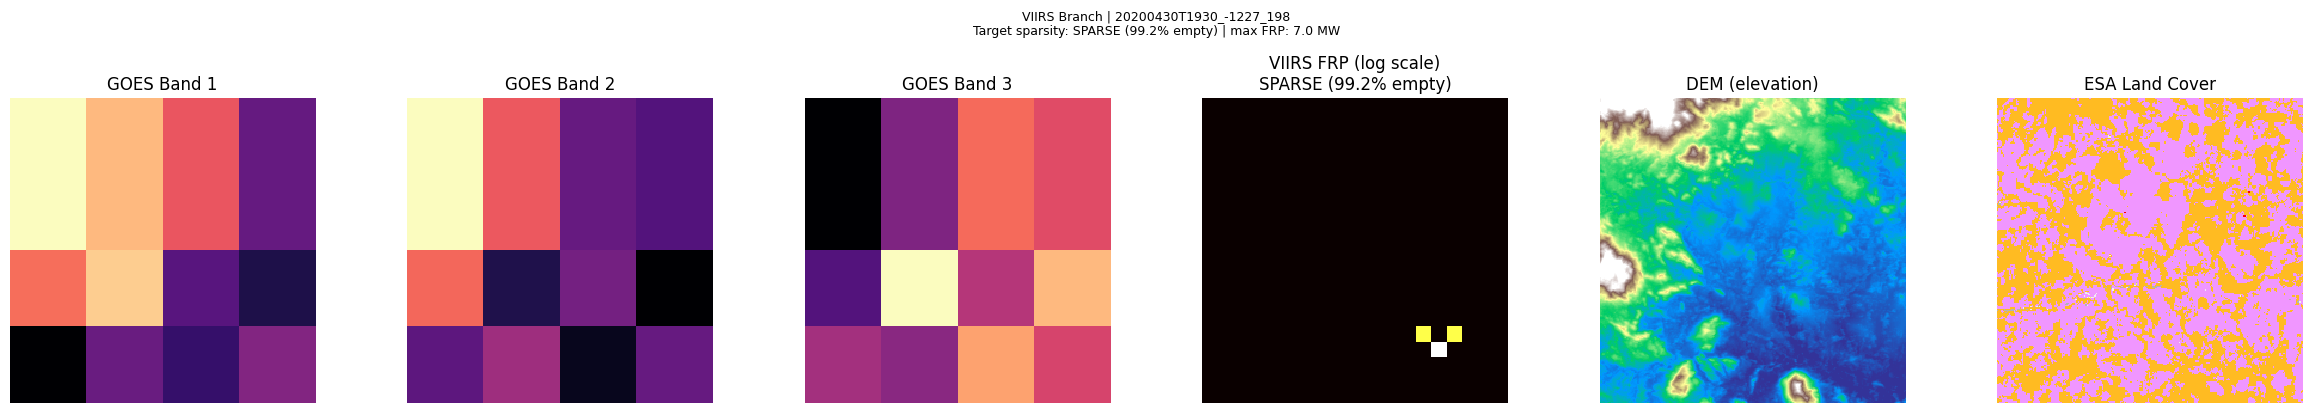

FRP unique values: [0.         6.63000011]
FRP max: 6.630000114440918, non-zero count: 2


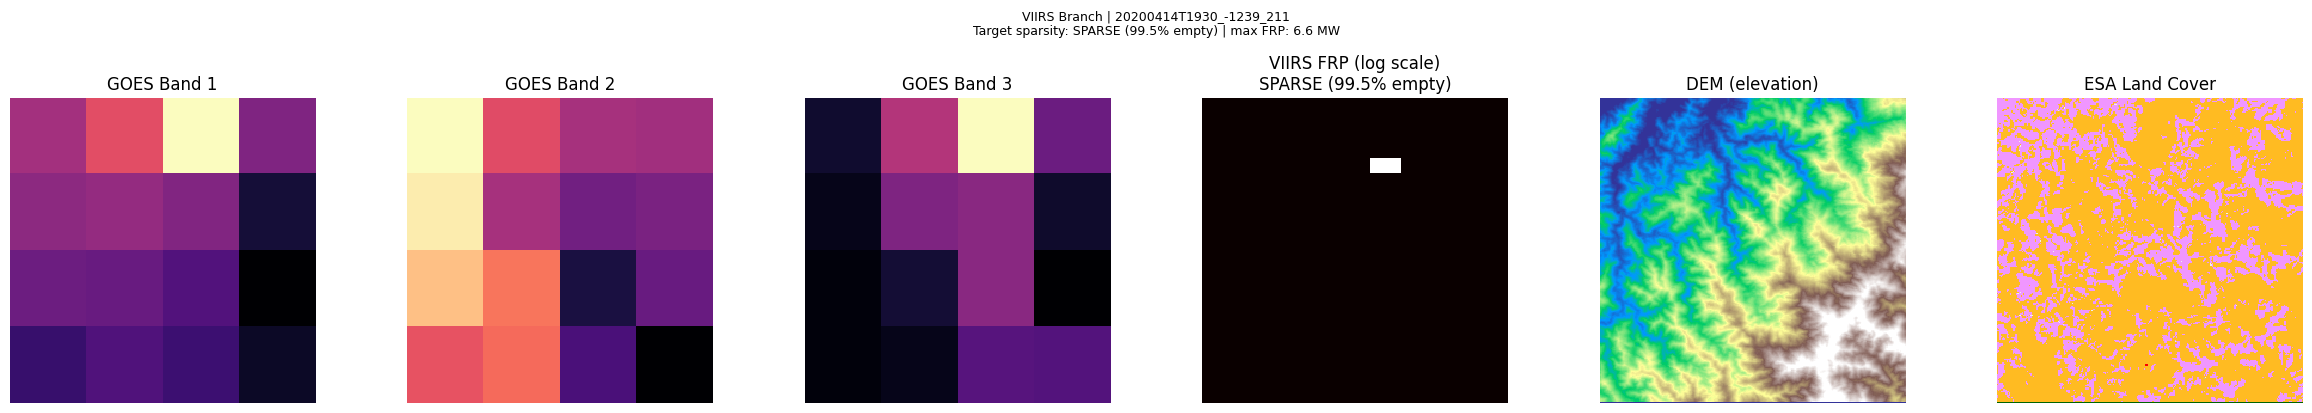

FRP unique values: [ 0.         17.78000069]
FRP max: 17.780000686645508, non-zero count: 3


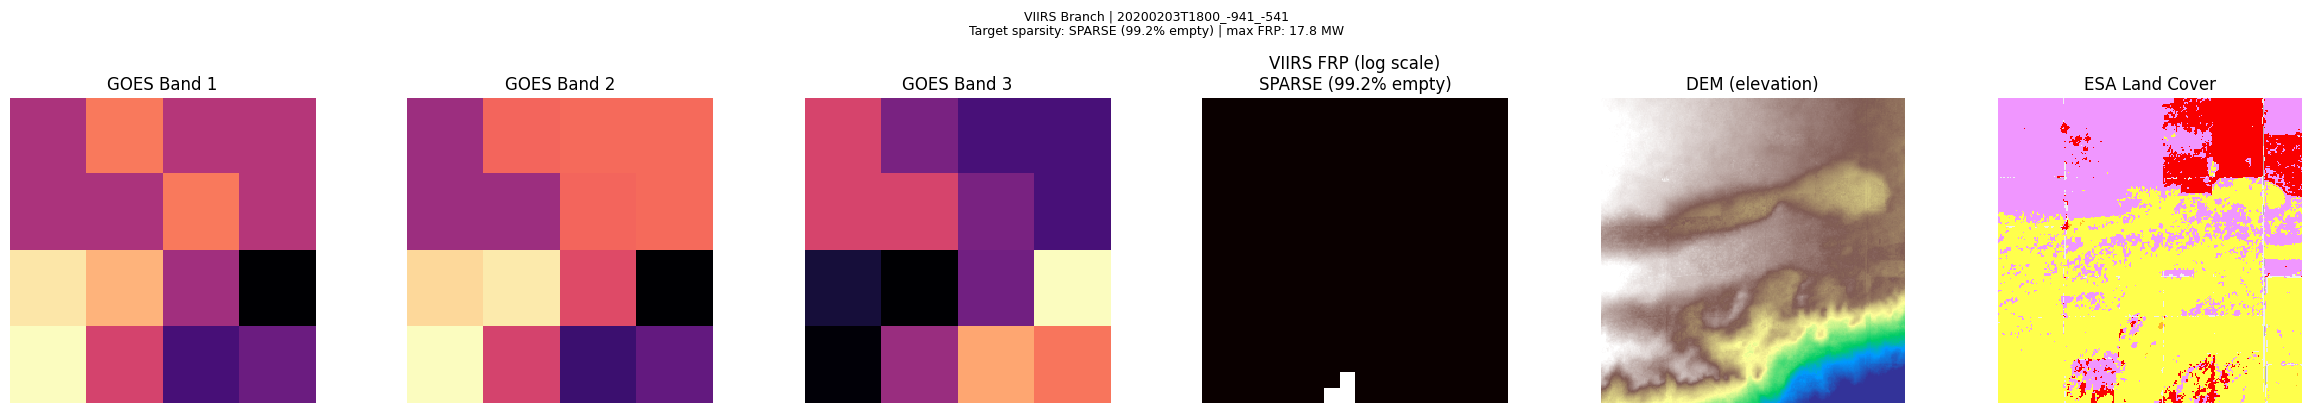

In [ ]:
# ── Plot: GOES / VIIRS / DEM / Landcover ──────────────────────────────────────

def plot_viirs_sample(manifest):
    sid = manifest['id']
    paths = manifest['paths']
    goes_data, _ = read_tif_from_gcs(paths['goes_input'].lstrip('/'))
    vr_data, _   = read_tif_from_gcs(paths['target'].lstrip('/'))
    cov_data, _  = read_tif_from_gcs(paths['covariates'].lstrip('/'))

    missing = [name for name, d in [('GOES', goes_data), ('VIIRS', vr_data), ('Covariates', cov_data)] if d is None]
    if missing:
        print(f'  [{sid}] Skipping — missing: {missing}')
        return

    viirs_frp = vr_data[0].astype(float)

    if (viirs_frp > 0).sum() == 0:
        print(f'  [{sid}] Skipping — no active fire pixels')
        return

    n_goes_channels = goes_data.shape[0]
    total_plots = n_goes_channels + 3  # N GOES channels + VIIRS + DEM + LC

    dem = cov_data[0].astype(float)
    lc  = cov_data[1].astype(float) if cov_data.shape[0] > 1 else np.zeros_like(dem)
    sp_label = classify_sparsity(viirs_frp)

    max_frp = 0.0 if np.all(~np.isfinite(viirs_frp)) else float(np.nanmax(viirs_frp))

    print(f"FRP unique values: {np.unique(viirs_frp)}")
    print(f"FRP max: {viirs_frp.max()}, non-zero count: {(viirs_frp > 0).sum()}")

    fig, axes = plt.subplots(1, total_plots, figsize=(4 * total_plots, 4))
    fig.suptitle(f'VIIRS Branch | {sid}\nTarget sparsity: {sp_label} | max FRP: {max_frp:.1f} MW', fontsize=9, y=1.02)

    # Plot all GOES channels dynamically
    for c in range(n_goes_channels):
        ch_data = goes_data[c].astype(float)
        axes[c].imshow(ch_data, cmap='magma', vmin=ch_data.min(), vmax=ch_data.max(), interpolation='nearest')
        axes[c].set_title(f'GOES Band {c+1}')

    # Plot Target and Covariates
    viirs_frp_clean = np.where(np.isfinite(viirs_frp), viirs_frp, 0.0)
    frp_display = np.log1p(viirs_frp_clean)
    frp_up = np.kron(frp_display, np.ones((8, 8)))
    frp_max = frp_up.max()
    
    if frp_max > 0:
        axes[n_goes_channels].imshow(frp_up / frp_max, cmap='hot', vmin=0, vmax=1, interpolation='nearest')
    else:
        axes[n_goes_channels].imshow(np.zeros_like(frp_up), cmap='hot', vmin=0, vmax=1, interpolation='nearest')
    axes[n_goes_channels].set_title(f'VIIRS FRP (log scale)\n{sp_label}')

    axes[n_goes_channels + 1].imshow(normalise(dem), cmap='terrain', interpolation='nearest')
    axes[n_goes_channels + 1].set_title('DEM (elevation)')

    axes[n_goes_channels + 2].imshow(lc, cmap=LC_CMAP, interpolation='nearest', vmin=0, vmax=100)
    axes[n_goes_channels + 2].set_title('ESA Land Cover')

    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

print('Plotting VIIRS samples...')
for m in viirs_samples:
    plot_viirs_sample(m)

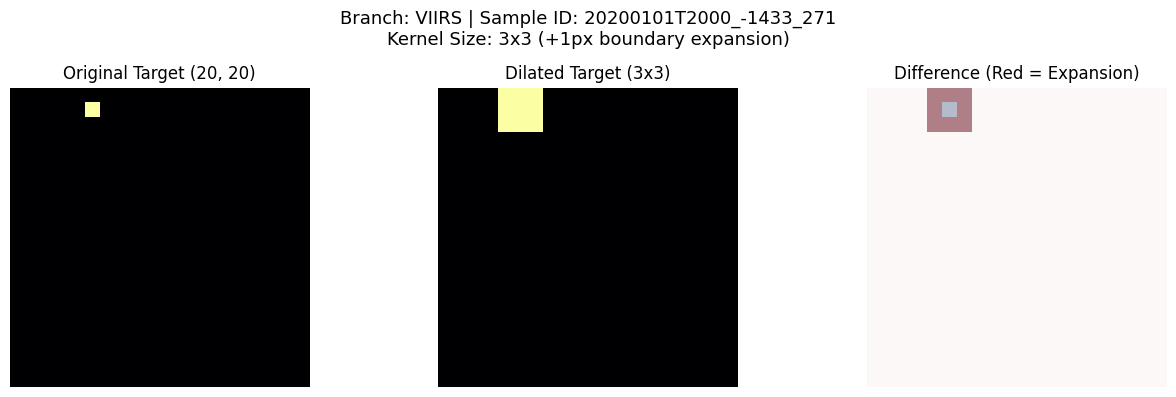

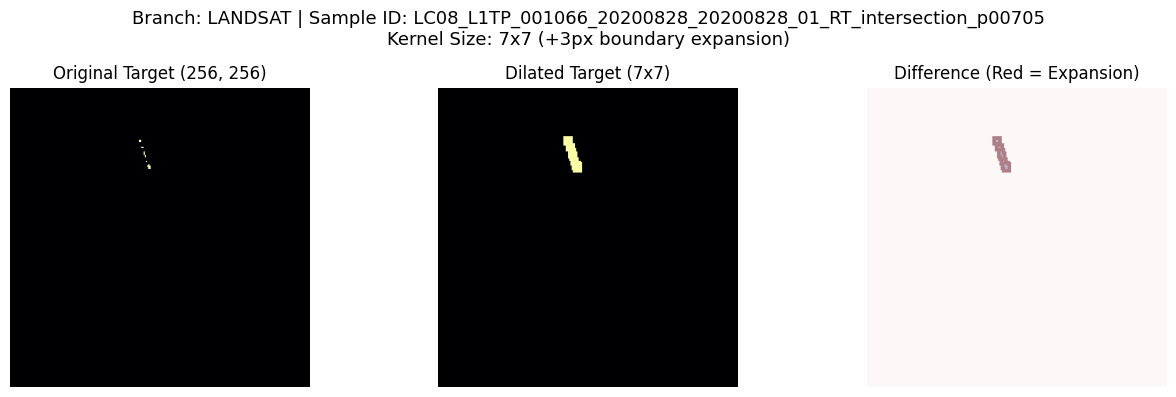

In [20]:
import json
import random
import matplotlib.pyplot as plt
import numpy as np
import rasterio
import torch
import torch.nn.functional as F
from google.cloud import storage

BUCKET_NAME = "wildfire-irp-data-th25"  # Replace with your bucket
OUTPUT_PREFIX = "processed_dataset_gcp"


def load_single_raster(bucket, gcs_path: str) -> torch.Tensor:
    """Download a single TIFF directly to memory without scanning manifests."""
    blob = bucket.blob(gcs_path)
    raw_bytes = blob.download_as_bytes()
    with rasterio.MemoryFile(raw_bytes) as mf:
        with mf.open() as src:
            data = src.read().astype(np.float32)
            nodata = src.nodata
    if nodata is not None:
        data[data == nodata] = 0.0
    data[~np.isfinite(data)] = 0.0
    return torch.from_numpy(data)


def apply_dilation(
    target_tensor: torch.Tensor, kernel_size: int = 3
) -> torch.Tensor:
    """Applies a 2D max-pooling operation with configurable kernel size."""
    bin_target = (target_tensor > 0).float()
    padding = kernel_size // 2
    dilated = F.max_pool2d(
        bin_target.unsqueeze(0),
        kernel_size=kernel_size,
        stride=1,
        padding=padding,
    ).squeeze(0)
    return (dilated > 0).float()


def fetch_and_plot_random_sample(
    branch: str, kernel_size: int = 3, sample_pool_size: int = 50
):
    client = storage.Client()
    bucket = client.bucket(BUCKET_NAME)

    manifest_prefix = f"{OUTPUT_PREFIX}/{branch}_pairs/manifest/"

    # Fetch a small pool of blobs to prevent notebook memory crashes
    blobs = list(
        bucket.list_blobs(prefix=manifest_prefix, max_results=sample_pool_size)
    )
    json_blobs = [b for b in blobs if b.name.endswith(".json")]

    if not json_blobs:
        raise FileNotFoundError(
            f"No JSON manifests found under gs://{BUCKET_NAME}/{manifest_prefix}"
        )

    # Pick one randomly
    random_blob = random.choice(json_blobs)
    manifest_data = json.loads(random_blob.download_as_text())

    sample_id = manifest_data.get("id", random_blob.name.split("/")[-1])
    target_gcs_path = manifest_data["paths"]["target"]

    # Download raw target tensor
    target_raw = load_single_raster(bucket, target_gcs_path)

    # Process original binary and dilated versions
    target_bin = (target_raw > 0).float().squeeze(0).numpy()
    target_dilated = (
        apply_dilation(target_raw, kernel_size=kernel_size).squeeze(0).numpy()
    )

    radius = kernel_size // 2

    # Plot
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    fig.suptitle(
        f"Branch: {branch.upper()} | Sample ID: {sample_id}\n"
        f"Kernel Size: {kernel_size}x{kernel_size} (+{radius}px boundary expansion)",
        fontsize=13,
    )

    axes[0].imshow(target_bin, cmap="inferno")
    axes[0].set_title(f"Original Target {target_bin.shape}")

    axes[1].imshow(target_dilated, cmap="inferno")
    axes[1].set_title(f"Dilated Target ({kernel_size}x{kernel_size})")

    # Difference overlay (Blue = Original, Red = Added dilation)
    diff = target_dilated - target_bin
    axes[2].imshow(target_bin, cmap="Blues", alpha=0.6, vmin=0, vmax=1)
    axes[2].imshow(diff, cmap="Reds", alpha=0.5, vmin=0, vmax=1)
    axes[2].set_title("Difference (Red = Expansion)")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


# Run comparison with branch-specific kernel sizes
# VIIRS: Keeps kernel=3 (1px radius expansion)
fetch_and_plot_random_sample("viirs", kernel_size=3)

# Landsat: Increased to kernel=7 (3px radius expansion / +90m expansion)
fetch_and_plot_random_sample("landsat", kernel_size=7)